# 03 · Evaluation: every table and figure for the report

This notebook loads the 18 models trained in notebooks 02a (CNN) and 02b (FNO) and produces all results.

- **Part 1: the promised checks.** CNN vs FNO trained at 128 points, matched training, 3 seeds.
  Roughness contrast with confidence intervals under all three roughness measures, and a start-time control.
- **Part 2: the competing explanation.** Models trained at 64 and 32 points, so the finer grids contain a lot of
  detail the training grid cannot see. Does the FNO's error now grow faster on rough inputs?

Every table is also saved as a `.csv` in `results/`, and the two report figures (PNG + PDF) in `figures/`.
All errors are shown **×10⁻³** unless stated otherwise.

In [1]:
import os, glob, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

DATA, CKPT, RES, FIG = os.path.join("..", "data"), "checkpoints", "results", "figures"
os.makedirs(RES, exist_ok=True); os.makedirs(FIG, exist_ok=True)
pd.set_option("display.precision", 3)

N_BOOT = 10000        # bootstrap resamples (lower it to 1000 for a quick run; intervals change slightly)
NAMES = ["smooth", "medium", "rough"]
GRIDS = [32, 64, 128, 256, 512]

## 0. Models and data

The two model classes are **copied unchanged from notebooks 02a/02b**. They are needed here to load the saved weights.

In [2]:
# ---------- models: identical to notebooks 02a/02b ----------
class GridLockedCNN(nn.Module):
    def __init__(self, hidden=64, kernel_size=3, num_layers=4):
        super().__init__()
        conv = lambda a, b: nn.Conv1d(a, b, kernel_size, padding=kernel_size // 2, padding_mode="circular")
        layers = [conv(1, hidden), nn.ReLU()]
        for _ in range(num_layers - 1):
            layers += [conv(hidden, hidden), nn.ReLU()]
        layers.append(conv(hidden, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, u):
        u = u[:, None, :]
        return (u + self.net(u))[:, 0, :]

def make_input(u):
    batch, n = u.shape
    x = torch.linspace(0, 1, n + 1, device=u.device)[:-1]
    return torch.stack([u, x.expand(batch, n)], dim=-1)

class SpectralConv1d(nn.Module):
    def __init__(self, cin, cout, modes):
        super().__init__()
        self.modes = modes
        self.weights = nn.Parameter(1 / (cin * cout) * torch.randn(cin, cout, modes, dtype=torch.cfloat))
    def forward(self, x):
        b, _, n = x.shape
        xf = torch.fft.rfft(x)
        out = torch.zeros(b, self.weights.shape[1], n // 2 + 1, dtype=torch.cfloat)
        k = min(self.modes, n // 2 + 1)
        out[:, :, :k] = torch.einsum("bix,iox->box", xf[:, :, :k], self.weights[:, :, :k])
        return torch.fft.irfft(out, n=n)

class FNO1d(nn.Module):
    def __init__(self, modes=64, width=64, n_layers=4):
        super().__init__()
        self.lift = nn.Linear(2, width)
        self.spec = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(n_layers)])
        self.w = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(n_layers)])
        self.proj = nn.Sequential(nn.Linear(width, 128), nn.GELU(), nn.Linear(128, 1))
    def forward(self, u):
        x = self.lift(make_input(u)).permute(0, 2, 1)
        for f, w in zip(self.spec, self.w):
            x = nn.functional.gelu(f(x) + w(x))
        return self.proj(x.permute(0, 2, 1)).squeeze(-1)

**Evaluation data on every grid.** All evaluation grids are made from the 512-point data by taking every k-th
point (notebook 01 checked that this gives exactly the kit's 128- and 256-point files). The buckets are the
tertiles from notebook 01: total variation (primary), sharpness (main check) and max slope (the check promised in M2),
all computed on the 128-point input. They are
computed once and reused on every grid.

`traj` records which of the 12 evaluation trajectories each row belongs to (rows 0–4 → trajectory 0, …).
The bootstrap needs it.

> **Which roughness measure makes the buckets?** **Total variation of the 128-point input** (the primary,
> pre-registered measure; `B_TV` in the code). It is used for **every** result in this notebook: the main table,
> the accuracy floor, the start-time control, all of Part 2 and both figures.
> The two other measures appear in **one place only**: section 5 repeats the main test with sharpness buckets
> (`B_SH`) and max-slope buckets (`B_MS`) to check that the conclusion does not depend on the choice.
> The start-time regression in section 6 uses the total-variation *value* itself (not the buckets).

In [3]:
d512 = np.load(os.path.join(DATA, "eval_512.npz"))
f512, t512 = d512["field"].astype(np.float32), d512["target"].astype(np.float32)
evalset = {N: (f512[:, ::512 // N], t512[:, ::512 // N]) for N in GRIDS}   # (inputs, targets) per grid
start = np.load(os.path.join(DATA, "eval_128.npz"))["context"][:, 0]      # start-time label per row
traj = np.arange(60) // 5                                                  # trajectory id per row

def rel_l2(pred, target):
    return np.linalg.norm(pred - target, axis=1) / np.linalg.norm(target, axis=1)

def tertile_buckets(score):
    order = np.argsort(score, kind="stable"); b = np.empty(len(score), dtype=int)
    for k, idx in enumerate(np.array_split(order, 3)):
        b[idx] = k
    return b

u128 = evalset[128][0]
u = u128.astype(np.float64)                                   # all three measures use the 128-point input
tv = np.abs(np.roll(u, -1, 1) - u).sum(1)                     # 1. total variation (primary)
slope = (np.roll(u, -1, 1) - np.roll(u, 1, 1)) / (2 / 128)    # 2. sharpness (main check):
sh = np.sqrt((slope ** 2).mean(1)) / np.sqrt(((u - u.mean(1, keepdims=True)) ** 2).mean(1))  #  RMS slope / RMS fluctuation
ms = np.abs(np.roll(u, -1, 1) - u).max(1)                     # 3. max slope (check promised in M2)
B_TV, B_SH, B_MS = tertile_buckets(tv), tertile_buckets(sh), tertile_buckets(ms)

# persistence baseline: "the next state equals the current state" -> error of the input itself
persist = {N: rel_l2(*evalset[N]) for N in GRIDS}

## 1. Predictions and per-example errors

For every checkpoint we predict on every grid **at least as fine as its training grid** and store the
relative $L^2$ error of each of the 60 examples. Each prediction is compared with the true solution **on the
same grid**.

We also store a **frequency split** of the 512-point error, which Part 2 uses. Section 9 explains it.
Briefly: by Parseval's theorem the squared error splits exactly into a part below the training grid's Nyquist
wavenumber and a part at or above it, $e^2 = e_{\text{low}}^2 + e_{\text{high}}^2$.

In [4]:
def band_split(err, y, kcut):
    # split each row's error into wavenumbers < kcut and >= kcut, both divided by ||y||
    Ef = np.fft.rfft(err.astype(np.float64), axis=1)
    w = np.ones(Ef.shape[1]); w[1:] = 2            # rfft stores each wavenumber k>0 once; its energy counts twice
    if err.shape[1] % 2 == 0:
        w[-1] = 1                                  # ... except the Nyquist wavenumber, which is stored once
    P = w * np.abs(Ef) ** 2 / err.shape[1]         # energy per wavenumber; sum over k = ||err||^2 (Parseval)
    Yn = np.linalg.norm(y, axis=1)
    return np.sqrt(P[:, :kcut].sum(1)) / Yn, np.sqrt(P[:, kcut:].sum(1)) / Yn

errs, hband = {}, {}
for path in sorted(glob.glob(os.path.join(CKPT, "*.pt"))):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    info = ck["info"]
    model = (GridLockedCNN if info["model"] == "cnn" else FNO1d)(**ck["config"])
    model.load_state_dict(ck["state"]); model.eval()
    key = (info["model"], info["n_train"], info["seed"])          # e.g. ("fno", 128, 0)
    with torch.no_grad():
        preds = {N: model(torch.tensor(evalset[N][0])).numpy() for N in GRIDS if N >= info["n_train"]}
    errs[key] = {N: rel_l2(p, evalset[N][1]) for N, p in preds.items()}
    hband[key] = band_split(preds[512] - evalset[512][1], evalset[512][1], info["n_train"] // 2)

print(len(errs), "checkpoints evaluated:", sorted(errs))

18 checkpoints evaluated: [('cnn', 32, 0), ('cnn', 32, 1), ('cnn', 32, 2), ('cnn', 64, 0), ('cnn', 64, 1), ('cnn', 64, 2), ('cnn', 128, 0), ('cnn', 128, 1), ('cnn', 128, 2), ('fno', 32, 0), ('fno', 32, 1), ('fno', 32, 2), ('fno', 64, 0), ('fno', 64, 1), ('fno', 64, 2), ('fno', 128, 0), ('fno', 128, 1), ('fno', 128, 2)]


## 2. The quantities we report

For a model trained on an $N_{\text{train}}$-point grid and one evaluation example:

- **Error** $e_N$: relative $L^2$ error on the $N$-point grid.
- **Growth** $\Delta_N = e_N - e_{N_\text{train}}$: how much worse the model gets when the grid is refined.
  We use the **difference**, not the ratio $e_N / e_{N_\text{train}}$. Rough inputs already have a large error at the
  training grid, so a ratio makes their growth look *smaller* (the CNN's ratio is 7.2× for rough inputs but 13.2×
  for smooth ones, although its rough growth is 16 times larger). The ratio mixes up base error and growth.
- **Contrast** $C_N = \overline{\Delta}_N^{\,\text{rough}} - \overline{\Delta}_N^{\,\text{smooth}}$: mean growth in the rough bucket minus mean
  growth in the smooth bucket. This is **the test statistic**. Our hypothesis H1 says $C_N > 0$ for the FNO.

**Seeds.** We first average each example's error over the 3 seeds, then compute the statistic. Separately, we
report the standard deviation of the statistic across the 3 seeds, so you can see how much retraining alone moves it.

**Confidence intervals: the cluster bootstrap.** The 5 examples of one trajectory are related (same initial
condition), so the 60 examples are not 60 independent observations. We resample **whole trajectories**: draw 12
trajectories with replacement from the 12, take all their rows, recompute the statistic, repeat 10,000 times.
The 2.5th and 97.5th percentiles give the 95% interval. If it contains 0, the data are consistent with "no effect".

In [5]:
seeds_of = lambda m, n: sorted(s for (mm, nn, s) in errs if mm == m and nn == n)

def seed_mean(m, n, N):
    # per-example error at grid N, averaged over the seeds of model m trained at n points
    return np.mean([errs[(m, n, s)][N] for s in seeds_of(m, n)], axis=0)

def growth(m, n, N, seed=None):
    # per-example growth e_N - e_train (seed-averaged, or for one seed)
    if seed is None:
        return seed_mean(m, n, N) - seed_mean(m, n, n)
    return errs[(m, n, seed)][N] - errs[(m, n, seed)][n]

def contrast(g, bucket, rows=None):
    # mean growth (rough) - mean growth (smooth), over the selected rows
    rows = np.arange(len(g)) if rows is None else rows
    return g[rows][bucket[rows] == 2].mean() - g[rows][bucket[rows] == 0].mean()

def cluster_bootstrap(stat_fn, n_boot=N_BOOT, seed=0):
    # 95% interval of stat_fn(rows), resampling whole evaluation trajectories
    rng = np.random.default_rng(seed)
    rows_of = {t: np.flatnonzero(traj == t) for t in range(12)}
    vals = [stat_fn(np.concatenate([rows_of[t] for t in rng.choice(12, size=12, replace=True)]))
            for _ in range(n_boot)]
    return np.percentile(vals, [2.5, 97.5])

x1e3 = lambda v: 1e3 * v

---
# Part 1 · Matched training, 3 seeds, and the promised checks

## 3. Main table

Mean error per bucket at 128, 256 and 512 points, for persistence, CNN and FNO trained at 128 points.
"± sd" is the standard deviation of the bucket mean across the 3 seeds.

In [6]:
rows = []
for k, b in enumerate(NAMES):
    sel = B_TV == k
    rows.append(dict(bucket=b, model="persistence", **{f"e{N}": x1e3(persist[N][sel].mean()) for N in (128, 256, 512)}))
    for m in ("cnn", "fno"):
        per_seed = {N: [errs[(m, 128, s)][N][sel].mean() for s in seeds_of(m, 128)] for N in (128, 256, 512)}
        row = dict(bucket=b, model=m.upper())
        for N in (128, 256, 512):
            row[f"e{N}"] = x1e3(np.mean(per_seed[N]))
            row[f"e{N} sd"] = x1e3(np.std(per_seed[N], ddof=1))
        row["ratio e512/e128"] = np.mean(per_seed[512]) / np.mean(per_seed[128])
        row["growth e512-e128"] = x1e3(np.mean(per_seed[512]) - np.mean(per_seed[128]))
        rows.append(row)
main = pd.DataFrame(rows)
main.to_csv(os.path.join(RES, "table_main.csv"), index=False, float_format="%.4g")
display(main.round(2).fillna(""))

,bucket,model,e128,e256,e512,e128 sd,e256 sd,e512 sd,ratio e512/e128,growth e512-e128
0,smooth,persistence,4.23,4.23,4.23,,,,,
1,smooth,CNN,0.25,2.20,3.24,0.05,0.04,0.04,13.17,2.99
2,smooth,FNO,0.43,0.52,0.55,0.06,0.12,0.15,1.29,0.12
3,medium,persistence,19.15,19.15,19.15,,,,,
4,medium,CNN,0.74,10.28,14.82,0.06,0.04,0.02,19.94,14.07
5,medium,FNO,1.15,1.36,1.43,0.04,0.22,0.28,1.24,0.28
6,rough,persistence,74.22,74.26,74.27,,,,,
7,rough,CNN,7.93,39.59,57.22,0.52,0.22,0.03,7.22,49.3
8,rough,FNO,10.56,10.70,10.72,0.2,0.2,0.2,1.01,0.15


**Reading it.**
- The **CNN** is the most accurate model at 128 points, but its error explodes on finer grids, and much more for
  rough inputs (growth 3 → 14 → 49 ×10⁻³). That is the behaviour we expect from a grid-locked model, so the
  positive control works.
- The **FNO** barely changes across grids in any bucket (growth 0.1–0.3 ×10⁻³).
- The seed standard deviations are small next to these differences.

## 4. Accuracy floor: are the models better than persistence?

A model could have tiny growth simply because it learned almost nothing (output ≈ input). Persistence tells us
whether the model is actually useful. "× better" = persistence error / model error.

In [7]:
rows = []
for m in ("cnn", "fno"):
    for k, b in enumerate(NAMES):
        for N in (128, 256, 512):
            e, p = seed_mean(m, 128, N)[B_TV == k].mean(), persist[N][B_TV == k].mean()
            rows.append(dict(model=m.upper(), bucket=b, grid=N, error=x1e3(e), persistence=x1e3(p),
                             times_better=p / e, below_persistence=e < p))
adm = pd.DataFrame(rows)
adm.to_csv(os.path.join(RES, "table_admissible.csv"), index=False, float_format="%.4g")
display(adm.pivot_table(index=["model", "bucket"], columns="grid", values="times_better").round(1))

grid           128   256   512
model bucket                  
CNN   medium  25.8   1.9   1.3
      rough    9.4   1.9   1.3
      smooth  17.2   1.9   1.3
FNO   medium  16.7  14.1  13.4
      rough    7.0   6.9   6.9
      smooth   9.9   8.2   7.7

The FNO is **6.9–16.7× better than persistence everywhere**, so its small growth is not a sign of a weak model.
The CNN drops to only **1.3× better** than persistence at 512 points.

## 5. The test: rough-minus-smooth contrast, under all three roughness measures

Section 2 defined the contrast $C_N$. We compute it at 256 and 512 points with the cluster-bootstrap interval and the
across-seed sd, once for each roughness measure from notebook 01:
1. **total variation**: the primary, pre-registered measure;
2. **sharpness**: the main robustness check; it ignores the wave's height and is less tied to start time;
3. **max slope**: the steepest single jump, the check promised in M2.

The growth of each example is the same in all three rows. Only the grouping into smooth / rough changes.

In [8]:
rows = []
for measure, B in (("total variation", B_TV), ("sharpness", B_SH), ("max slope", B_MS)):
    for m in ("cnn", "fno"):
        for N in (256, 512):
            g = growth(m, 128, N)                                         # seed-averaged growth per example
            lo, hi = cluster_bootstrap(lambda r: contrast(g, B, r))
            per_seed = [contrast(growth(m, 128, N, s), B) for s in seeds_of(m, 128)]
            rows.append({"measure": measure, "model": m.upper(), "grid": N,
                         "growth smooth": x1e3(g[B == 0].mean()), "growth medium": x1e3(g[B == 1].mean()),
                         "growth rough": x1e3(g[B == 2].mean()),
                         "contrast C": x1e3(contrast(g, B)), "CI low": x1e3(lo), "CI high": x1e3(hi),
                         "seed sd": x1e3(np.std(per_seed, ddof=1))})
con = pd.DataFrame(rows)
con.to_csv(os.path.join(RES, "table_contrast.csv"), index=False, float_format="%.4g")
display(con.round(3))

,measure,model,grid,growth smooth,growth medium,growth rough,contrast C,CI low,CI high,seed sd
0,total variation,CNN,256,1.950,9.533,31.663,29.712,22.665,37.388,0.289
1,total variation,CNN,512,2.992,14.073,49.296,46.304,34.949,58.748,0.481
2,total variation,FNO,256,0.090,0.213,0.142,0.052,-0.176,0.291,0.093
3,total variation,FNO,512,0.122,0.279,0.155,0.033,-0.257,0.325,0.122
4,sharpness,CNN,256,6.316,10.775,26.054,19.738,11.608,30.829,0.284
5,sharpness,CNN,512,9.478,16.141,40.741,31.263,18.388,48.928,0.492
6,sharpness,FNO,256,0.139,0.119,0.186,0.046,-0.165,0.304,0.131
7,sharpness,FNO,512,0.181,0.148,0.226,0.045,-0.209,0.338,0.163
8,max slope,CNN,256,1.840,9.531,31.775,29.935,22.198,39.161,0.351
9,max slope,CNN,512,2.846,14.533,48.981,46.135,33.189,61.200,0.524


**Reading it.**
- **CNN:** a large contrast with an interval far from 0 under all three measures (≈46 ×10⁻³ for total variation and max
  slope, ≈31 for sharpness). The protocol detects a roughness effect whichever way roughness is defined.
- **FNO:** every interval contains 0, at both grids and under all three measures. Its largest upper bound (≈0.4) is a
  small fraction of the CNN's lower bounds (≈18–35).
- **Why the sharpness row matters:** sharpness ranks the inputs quite differently from total variation (Spearman 0.40)
  and is less tied to start time, yet the conclusion is the same. So the result is not an artefact of the chosen measure.

## 6. Start-time control

Rough inputs come almost only from the first two start times (notebook 01). Is the CNN's "roughness effect" just
an "early-time effect"? And could an FNO roughness effect be hiding behind the time effect?

We fit a linear regression of each example's growth on its standardised log total variation:
$$\Delta_{512} = a_{t} + \beta \cdot z(\log \mathrm{TV}) + \text{noise},$$
- **without control:** a single intercept $a$ for everyone;
- **with control:** one intercept $a_t$ **per start time** ("fixed effects"). Then $\beta$ can only use differences in
  roughness **between examples with the same start time**. It is the roughness effect with time held fixed.

$\beta$ is the change in growth (×10⁻³) per one standard deviation of log TV. The interval is again a cluster bootstrap.

In [9]:
times = np.unique(start)
z = (np.log(tv) - np.log(tv).mean()) / np.log(tv).std()      # standardised log total variation

def beta(g, rows, fixed_effects):
    # least-squares slope on z, with either one intercept per start time or a single intercept
    if fixed_effects:
        cols = [z[rows]] + [(start[rows] == t).astype(float) for t in times]
    else:
        cols = [z[rows], np.ones(len(rows))]
    coef, *_ = np.linalg.lstsq(np.stack(cols, 1), g[rows], rcond=None)
    return coef[0]

rows = []
for m in ("cnn", "fno"):
    for N in (256, 512):
        g = growth(m, 128, N)
        for fe in (False, True):
            lo, hi = cluster_bootstrap(lambda r: beta(g, r, fe))
            rows.append(dict(model=m.upper(), grid=N, control="start-time fixed effects" if fe else "none",
                             beta=x1e3(beta(g, np.arange(60), fe)), CI_low=x1e3(lo), CI_high=x1e3(hi)))
st = pd.DataFrame(rows)
st.to_csv(os.path.join(RES, "table_starttime.csv"), index=False, float_format="%.4g")
display(st.round(3))

,model,grid,control,beta,CI_low,CI_high
0,CNN,256,none,10.600,7.045,36.032
1,CNN,256,start-time fixed effects,4.652,3.363,32.279
2,CNN,512,none,16.525,10.825,56.920
3,CNN,512,start-time fixed effects,7.024,5.068,49.866
4,FNO,256,none,0.065,-0.061,0.152
5,FNO,256,start-time fixed effects,0.086,0.037,0.460
6,FNO,512,none,0.075,-0.099,0.161
7,FNO,512,start-time fixed effects,0.108,0.047,0.587


**Reading it.**
- **CNN:** the slope roughly halves when start time is controlled (16.5 → 7.0 at 512 points) but stays clearly
  positive. Part of its apparent roughness effect is shared with start time, and a real roughness effect remains.
- **FNO:** with start time controlled there *is* a small positive association (≈0.1 ×10⁻³ per SD, interval just above 0).
  It is about **65× smaller than the CNN's**. Report it honestly as a statistically detectable but very small effect.
- The intervals are lopsided (upper ends far from the estimate) because a few very rough trajectories have a lot of
  influence on a slope. Treat their exact width with care.

## 7. Figure 1: growth per bucket (for the report)

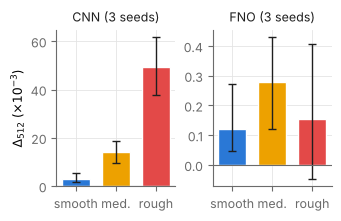

In [10]:
INK, MUTED, GRIDC = "#1f1f1f", "#6b6b6b", "#e4e4e4"
COLORS = ["#2a78d6", "#eda100", "#e34948"]         # smooth -> rough: blue -> yellow -> red
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRIDC, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False})

def bucket_ci(g, k, n_boot=2000):
    # bootstrap interval of the mean growth within bucket k
    return cluster_bootstrap(lambda r: g[r][B_TV[r] == k].mean(), n_boot)

fig, axes = plt.subplots(1, 2, figsize=(3.3, 2.1), constrained_layout=True)
for ax, m in zip(axes, ("cnn", "fno")):
    g = growth(m, 128, 512)
    for k in range(3):
        mean = g[B_TV == k].mean(); lo, hi = bucket_ci(g, k)
        ax.bar(k, x1e3(mean), width=0.7, color=COLORS[k], edgecolor="white", linewidth=1)
        ax.errorbar(k, x1e3(mean), yerr=[[x1e3(max(mean - lo, 0))], [x1e3(max(hi - mean, 0))]],
                    color=INK, capsize=3, lw=1)
    ax.set_xticks(range(3)); ax.set_xticklabels(["smooth", "med.", "rough"]); ax.axhline(0, color=MUTED, lw=0.8)
    ax.set_title(f"{m.upper()} ({len(seeds_of(m, 128))} seeds)", color=INK, fontsize=9)
axes[0].set_ylabel(r"$\Delta_{512}$ ($\times10^{-3}$)")
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(FIG, f"fig_growth_main.{ext}"), dpi=300)
plt.show()

Note the two y-axes differ by a factor of ~150. The FNO's bars are drawn on their own scale so that you can see
their intervals at all.

## 8. Part 1 decision

The rule fixed in M2: H1 is **supported** if the FNO's contrast is positive with intervals excluding 0 at both
256 and 512 points, and is a substantial fraction of the CNN's.

In [11]:
fno = con[(con.model == "FNO")]
excl_zero = ((fno["CI low"] > 0) | (fno["CI high"] < 0)).any()
print("Any FNO contrast interval that excludes 0?      ", excl_zero)
cnn_lo = con[(con.model == "CNN") & (con.grid == 512) & (con.measure == "total variation")]["CI low"].item()
fno_hi = con[(con.model == "FNO") & (con.grid == 512) & (con.measure == "total variation")]["CI high"].item()
print(f"FNO upper bound / CNN lower bound at 512 points:  {fno_hi / cnn_lo:.1%}")
print("=> H1 not supported for the FNO (with the small within-start-time association from section 6 as a nuance).")

Any FNO contrast interval that excludes 0?       False
FNO upper bound / CNN lower bound at 512 points:  0.9%
=> H1 not supported for the FNO (with the small within-start-time association from section 6 as a nuance).


---
# Part 2 · The competing explanation: "nothing to fail on"

Notebook 01 showed that at a 128-point training grid the finer grids add almost no new detail. So Part 1's null
result could mean "the FNO is invariant" **or** "there was nothing to fail on". To tell these apart, we trained both
models at **64 and 32 points**, where the finer grids hold a lot of detail the training grid cannot represent, and
repeat the same test: growth from the training grid to 512 points, per bucket.

## 9. How much unseen detail is there, per training grid?

The **truncation reference** (notebook 01, section 4): the error of the 512-point target with every wavenumber at or
above the training Nyquist ($N_\text{train}/2$) deleted. It is the error a perfect model would make if it could add
**no** detail finer than its training grid.

In [12]:
def band_limit(u, kmax):
    U = np.fft.rfft(u.astype(np.float64), axis=1); U[:, kmax:] = 0
    return np.fft.irfft(U, n=u.shape[1], axis=1)

x512, y512 = (a.astype(np.float64) for a in evalset[512])
E = np.abs(np.fft.rfft(x512, axis=1)) ** 2
trunc, rows = {}, []
for n in (32, 64, 128):
    frac = E[:, n // 2:].sum(1) / E.sum(1)
    tr_err = rel_l2(band_limit(y512, n // 2), y512)
    for k, b in enumerate(NAMES):
        trunc[(n, b)] = tr_err[B_TV == k].mean()
        rows.append(dict(training_grid=n, bucket=b, energy_above_nyquist=np.median(frac[B_TV == k]),
                         truncation_reference=x1e3(trunc[(n, b)])))
unres = pd.DataFrame(rows)
unres.to_csv(os.path.join(RES, "table_unresolved.csv"), index=False, float_format="%.4g")
display(unres.pivot(index="training_grid", columns="bucket", values="truncation_reference")[NAMES].round(2))

bucket,smooth,medium,rough
training_grid,,,
32,0.41,9.22,25.35
64,0.16,1.10,6.30
128,0.11,0.44,2.47


At 32 points the rough bucket's unseen content is about **10× larger** than at 128 points (≈25 vs ≈2.5 ×10⁻³).
If the FNO's transfer depends on roughness, it should show here.

## 10. Growth and contrast for every training grid

Same quantities as Part 1, now with growth measured from each model's **own** training grid:
$\Delta = e_{512} - e_{N_\text{train}}$.

In [13]:
rows, trainres = [], {}
for m in ("cnn", "fno"):
    for n in (32, 64, 128):
        g = growth(m, n, 512)
        lo, hi = cluster_bootstrap(lambda r: contrast(g, B_TV, r))
        per_seed = [contrast(growth(m, n, 512, s), B_TV) for s in seeds_of(m, n)]
        ok = all(seed_mean(m, n, N)[B_TV == k].mean() < persist[N][B_TV == k].mean()
                 for N in GRIDS if N >= n for k in range(3))
        trainres[(m, n)] = dict(gb=[g[B_TV == k].mean() for k in range(3)],
                                gb_ci=[bucket_ci(g, k) for k in range(3)])
        rows.append({"model": m.upper(), "training grid": n,
                     "e_train smooth": x1e3(seed_mean(m, n, n)[B_TV == 0].mean()),
                     "e_train rough": x1e3(seed_mean(m, n, n)[B_TV == 2].mean()),
                     "growth smooth": x1e3(trainres[(m, n)]["gb"][0]),
                     "growth medium": x1e3(trainres[(m, n)]["gb"][1]),
                     "growth rough": x1e3(trainres[(m, n)]["gb"][2]),
                     "contrast C512": x1e3(contrast(g, B_TV)), "CI low": x1e3(lo), "CI high": x1e3(hi),
                     "seed sd": x1e3(np.std(per_seed, ddof=1)), "below persistence everywhere": ok})
tres = pd.DataFrame(rows)
tres.to_csv(os.path.join(RES, "table_trainres.csv"), index=False, float_format="%.4g")
display(tres.round(3))

,model,training grid,e_train smooth,e_train rough,growth smooth,growth medium,growth rough,contrast C512,CI low,CI high,seed sd,below persistence everywhere
0,CNN,32,0.339,18.071,3.694,16.800,52.099,48.405,36.738,61.405,0.484,True
1,CNN,64,0.228,10.045,3.520,16.256,55.789,52.270,40.011,65.300,0.441,True
2,CNN,128,0.246,7.929,2.992,14.073,49.296,46.304,34.949,58.748,0.481,True
3,FNO,32,0.566,21.839,0.481,0.650,-5.060,-5.541,-16.209,0.401,0.450,True
4,FNO,64,0.474,11.659,0.437,0.626,-0.605,-1.042,-3.018,0.366,0.126,True
5,FNO,128,0.426,10.563,0.122,0.279,0.155,0.033,-0.257,0.325,0.122,True


**Reading it.**
- **CNN:** a large positive contrast (46–52) at every training grid. The control keeps working.
- **FNO:** even with 10× more unseen detail (training at 32 points), the contrast **never becomes positive**.
  The rough bucket's error actually **falls** on finer grids (growth −5.1 ×10⁻³ at 32 points), while smooth and medium
  inputs get slightly worse.

Why would a rough input's error *drop* on a finer grid? The next section answers that.

> **Caveat for the report.** At coarse training grids, $e_{N_\text{train}}$ is measured on samples that cannot represent
> rough inputs well, so "growth" partly reflects a change in *what is being measured*. The frequency split below
> does not have this problem, which is why it is the stronger evidence.

## 11. Frequency split: does the FNO recover the unseen detail?

Split the 512-point error at the training Nyquist $k_c = N_\text{train}/2$: $e_{512}^2 = e_\text{low}^2 + e_\text{high}^2$.
The high part is the error on exactly the scales the model never saw during training. Compare it with the truncation
reference $T$ (the high-band error of a prediction with **no** fine detail at all):

$$\text{ratio} = e_\text{high} / T \qquad
\begin{cases}
< 1 & \text{the model recovers part of the real fine-scale detail} \\
= 1 & \text{as good as adding nothing} \\
> 1 & \text{the model adds wrong fine-scale detail}
\end{cases}$$

"Recovered" in the table is $1 - \text{ratio}$, the share of the unseen detail the model gets right.

In [14]:
rows = []
for m in ("cnn", "fno"):
    for n in (32, 64, 128):
        low = np.mean([hband[(m, n, s)][0] for s in seeds_of(m, n)], axis=0)    # seed-averaged, per example
        high = np.mean([hband[(m, n, s)][1] for s in seeds_of(m, n)], axis=0)
        for k, b in enumerate(NAMES):
            sel = B_TV == k
            ratio = high[sel].mean() / trunc[(n, b)]
            rows.append({"model": m.upper(), "training grid": n, "bucket": b,
                         "e512": x1e3(seed_mean(m, n, 512)[sel].mean()), "low-band error": x1e3(low[sel].mean()),
                         "high-band error": x1e3(high[sel].mean()), "truncation reference": x1e3(trunc[(n, b)]),
                         "ratio": ratio, "recovered": 1 - ratio})
band = pd.DataFrame(rows)
band.to_csv(os.path.join(RES, "table_bandsplit.csv"), index=False, float_format="%.4g")
display(band[band.model == "FNO"].pivot(index="training grid", columns="bucket", values="ratio")[NAMES].round(2))
display(band.round(3))

bucket,smooth,medium,rough
training grid,,,
32,1.62,0.44,0.51
64,3.48,1.09,0.74
128,1.96,1.36,0.77


,model,training grid,bucket,e512,low-band error,high-band error,truncation reference,ratio,recovered
0,CNN,32,smooth,4.033,4.032,0.084,0.413,0.202,0.798
1,CNN,32,medium,18.085,17.603,3.186,9.225,0.345,0.655
2,CNN,32,rough,70.171,66.490,17.870,25.352,0.705,0.295
3,CNN,64,smooth,3.748,3.748,0.044,0.164,0.270,0.730
4,CNN,64,medium,17.010,16.984,0.617,1.098,0.562,0.438
5,CNN,64,rough,65.834,65.233,5.768,6.299,0.916,0.084
6,CNN,128,smooth,3.238,3.237,0.040,0.113,0.353,0.647
7,CNN,128,medium,14.816,14.815,0.155,0.440,0.353,0.647
8,CNN,128,rough,57.225,57.187,1.686,2.472,0.682,0.318
9,FNO,32,smooth,1.047,0.753,0.669,0.413,1.618,-0.618


**Reading the FNO ratios.**
- **Rough inputs: ratio < 1** (0.51–0.77). The FNO **recovers 23–49%** of the detail it never saw in training. It really
  uses the extra information on finer grids, which is why the rough bucket's error can fall. This is evidence of
  genuine transfer, not "nothing to fail on".
- **Smooth inputs: ratio > 1** (1.6–3.5). The FNO **adds spurious fine-scale wiggles** where the true field has
  almost none. This is where its small growth comes from. It is a property of the model, not of roughness.
  Notebook 04 (figure H) finds a concrete source: **about half of the FNO's growth comes from error at the domain
  edges**, probably because its position input $x$ jumps from 1 back to 0 there while the field is periodic. The rest
  is consistent with aliasing from the point-wise non-linearities (GELU applied on the grid creates high frequencies
  that land differently on each grid), the problem CNO was designed to fix (Bartolucci et al., 2023).
- The CNN also gets ratios below 1, but its *low-band* error is huge (it fails on the scales it did see), so this
  does not help it.

## 12. Figure 2: the training-resolution experiment (for the report)

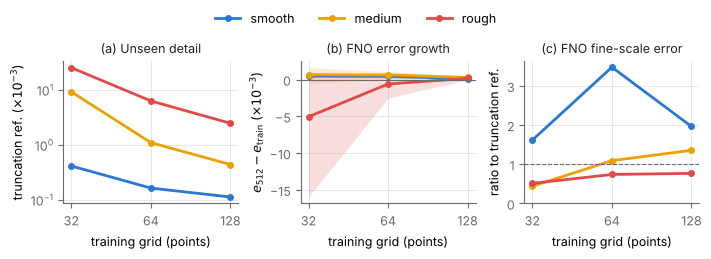

In [15]:
ns = [32, 64, 128]
fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.5), constrained_layout=True)
def xaxis(ax):
    ax.set_xscale("log", base=2); ax.set_xticks(ns); ax.set_xticklabels(ns); ax.minorticks_off()
    ax.set_xlabel("training grid (points)")

ax = axes[0]                                     # (a) how much unseen detail exists
for k in range(3):
    ax.plot(ns, [x1e3(trunc[(n, NAMES[k])]) for n in ns], "-o", color=COLORS[k], lw=2, ms=4, label=NAMES[k])
ax.set_yscale("log"); xaxis(ax)
ax.set_title("(a) Unseen detail", color=INK, fontsize=9)
ax.set_ylabel(r"truncation ref. ($\times10^{-3}$)")

ax = axes[1]                                     # (b) the pre-registered growth measure, with 95% CI
for k in range(3):
    y = [x1e3(trainres[("fno", n)]["gb"][k]) for n in ns]
    lo = [x1e3(trainres[("fno", n)]["gb_ci"][k][0]) for n in ns]
    hi = [x1e3(trainres[("fno", n)]["gb_ci"][k][1]) for n in ns]
    ax.fill_between(ns, lo, hi, color=COLORS[k], alpha=0.18, lw=0)
    ax.plot(ns, y, "-o", color=COLORS[k], lw=2, ms=4)
ax.axhline(0, color=MUTED, lw=0.8); xaxis(ax)
ax.set_title("(b) FNO error growth", color=INK, fontsize=9)
ax.set_ylabel(r"$e_{512}-e_{\mathrm{train}}$ ($\times10^{-3}$)")

ax = axes[2]                                     # (c) fine-scale error relative to adding nothing
for k in range(3):
    ax.plot(ns, [band[(band.model == "FNO") & (band["training grid"] == n) & (band.bucket == NAMES[k])]["ratio"].item()
                 for n in ns], "-o", color=COLORS[k], lw=2, ms=4)
ax.axhline(1, color=MUTED, lw=0.8, ls="--")
xaxis(ax); ax.set_ylim(bottom=0)
ax.set_title("(c) FNO fine-scale error", color=INK, fontsize=9)
ax.set_ylabel("ratio to truncation ref.")

fig.legend(*axes[0].get_legend_handles_labels(), loc="outside upper center", ncol=3)
for ext in ("png", "pdf"):
    fig.savefig(os.path.join(FIG, f"fig_trainres.{ext}"), dpi=300)
plt.show()

---
# Conclusion

1. **Part 1.** With matched training and 3 seeds, the FNO's cross-resolution error growth does **not depend on input
   roughness**: the contrast is ≈0 with intervals containing 0, under three roughness measures, while the CNN control shows a
   large effect. Controlling for start time leaves a very small positive association for the FNO, about 65× smaller than the CNN's.
2. **Part 2.** The main alternative explanation, that the finer grids simply had nothing new in them, is ruled out. When the
   finer grids hold a lot of unseen detail, the FNO still shows no roughness-dependent growth. On rough inputs it recovers
   part of that detail.
3. **Mechanism.** The FNO's small growth comes from spurious fine-scale content, mostly on **smooth** inputs. About half
   of it sits at the domain edges (notebook 04, figure H), probably from the non-periodic position input; the rest is
   consistent with aliasing from point-wise non-linearities. Natural next steps: a periodic position encoding
   ($\sin 2\pi x$, $\cos 2\pi x$) and an alias-free architecture (CNO).

All numbers above are saved in `results/`. `RESULTS.md` has the same results in prose with paste-ready sentences for the report.